In [1]:
# Step 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [2]:
# Step 2: Install required libraries
!pip install -q transformers datasets accelerate evaluate scikit-learn matplotlib seaborn torch



In [3]:
# Step 3: Verify GPU Availability
import os
import sys
import math
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Reproducibility seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 50)
print(f"PyTorch Version: {torch.__version__}")
print(f"Compute Device:  {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU Model:       {torch.cuda.get_device_name(0)}")
    print(f"VRAM Available:  {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("[NOTE] Running on CPU. For faster training, go to Runtime -> Change runtime type -> T4 GPU.")
print("=" * 50)



PyTorch Version: 2.11.0+cu130
Compute Device:  cuda
GPU Model:       Tesla T4
VRAM Available:  14.56 GB


 
# Part 1: Midsem Examination Solutions



 
## Question 2: Beam Search Decoding Algorithm

### Problem Statement
You are designing a neural language model. The vocabulary is restricted to:
$$\mathcal{V} = \{\text{cat}, \text{sat}, \text{mat}, </s>\}$$
where `</s>` represents the End-Of-Sentence token. The conditional probabilities $P(w_t \mid w_1, \dots, w_{t-1})$ calculated across three time steps are as follows:

* **At $t=1$:**
  $$P(\text{cat} \mid <s>) = 0.5, \quad P(\text{sat} \mid <s>) = 0.3, \quad P(\text{mat} \mid <s>) = 0.2$$
  *(where `<s>` is the Start-of-Sentence token and is not part of the vocabulary)*

* **At $t=2$:**
  $$P(\text{sat} \mid \text{cat}) = 0.6, \quad P(\text{mat} \mid \text{cat}) = 0.3, \quad P(</s> \mid \text{cat}) = 0.1$$
  $$P(\text{cat} \mid \text{sat}) = 0.2, \quad P(\text{mat} \mid \text{sat}) = 0.7, \quad P(</s> \mid \text{sat}) = 0.1$$

* **At $t=3$:**
  $$P(\text{mat} \mid \text{cat sat}) = 0.8, \quad P(</s> \mid \text{cat sat}) = 0.2$$
  $$P(\text{cat} \mid \text{sat mat}) = 0.1, \quad P(</s> \mid \text{sat mat}) = 0.9$$

**Tasks:**
1. Trace the Beam Search decoding algorithm with beam width $k = 2$ across time steps $t=1, 2, 3$.
2. At each step, compute cumulative probabilities for all expanded hypotheses and state the top-$k$ retained candidates.
3. Identify the final output sequence produced by beam search.


In [4]:
# Programmatic Verification of Question 2 (Beam Search)
probs_t1 = {'cat': 0.5, 'sat': 0.3, 'mat': 0.2}

probs_t2 = {
    'cat': {'sat': 0.6, 'mat': 0.3, '</s>': 0.1},
    'sat': {'cat': 0.2, 'mat': 0.7, '</s>': 0.1}
}

probs_t3 = {
    ('cat', 'sat'): {'mat': 0.8, '</s>': 0.2},
    ('sat', 'mat'): {'cat': 0.1, '</s>': 0.9}
}

k = 2

# t = 1
step1 = sorted(probs_t1.items(), key=lambda x: -x[1])
retained_t1 = step1[:k]
print("t=1 Retained:", retained_t1)

# t = 2
step2 = []
for (prev, p_prev) in retained_t1:
    for nxt, trans in probs_t2[prev].items():
        step2.append(([prev, nxt], p_prev * trans))
step2.sort(key=lambda x: -x[1])
retained_t2 = step2[:k]
print("t=2 Retained:", [(' '.join(h), round(p, 4)) for h, p in retained_t2])

# t = 3
step3 = []
for (seq, p_seq) in retained_t2:
    for nxt, trans in probs_t3[tuple(seq)].items():
        step3.append((seq + [nxt], p_seq * trans))
step3.sort(key=lambda x: -x[1])
retained_t3 = step3[:k]
print("t=3 Retained:", [(' '.join(h), round(p, 4)) for h, p in retained_t3])

best_completed = max([c for c in step3 if c[0][-1] == '</s>'], key=lambda x: x[1])
print(f"\nFinal Completed Output: '{' '.join(best_completed[0])}' with prob {best_completed[1]:.4f}")



t=1 Retained: [('cat', 0.5), ('sat', 0.3)]
t=2 Retained: [('cat sat', 0.3), ('sat mat', 0.21)]
t=3 Retained: [('cat sat mat', 0.24), ('sat mat </s>', 0.189)]

Final Completed Output: 'sat mat </s>' with prob 0.1890



## Question 4: Byte Pair Encoding (BPE) Algorithm

### Problem Statement
Corpus:
```
low lower low lower lowest
low lowest low lowest
low new
newest widest widest
new widest
```
**Tasks:**
1. Apply BPE for **2 merges**.
2. Show the **vocabulary** and the **merge rules**.


 


In [5]:
# Programmatic Verification of Question 4 (BPE)
from collections import defaultdict

corpus_dict = {
    tuple(list("low") + ["</w>"]): 5,
    tuple(list("lower") + ["</w>"]): 2,
    tuple(list("lowest") + ["</w>"]): 3,
    tuple(list("new") + ["</w>"]): 2,
    tuple(list("newest") + ["</w>"]): 1,
    tuple(list("widest") + ["</w>"]): 3
}

def get_stats(vocab):
    pairs = defaultdict(int)
    for word, freq in vocab.items():
        for i in range(len(word) - 1):
            pairs[(word[i], word[i+1])] += freq
    return pairs

def merge_vocab(pair, v_in):
    v_out = {}
    for word, freq in v_in.items():
        w_out, i = [], 0
        while i < len(word):
            if i < len(word) - 1 and word[i] == pair[0] and word[i+1] == pair[1]:
                w_out.append(pair[0] + pair[1])
                i += 2
            else:
                w_out.append(word[i])
                i += 1
        v_out[tuple(w_out)] = freq
    return v_out

cur = corpus_dict
merges = []
for m in range(2):
    stats = sorted(get_stats(cur).items(), key=lambda x: (-x[1], x[0]))
    best_pair, freq = stats[0]
    merges.append(best_pair)
    cur = merge_vocab(best_pair, cur)
    print(f"Merge {m+1}: {best_pair[0]} + {best_pair[1]} -> '{best_pair[0]+best_pair[1]}' (freq {freq})")

print("\nFinal Corpus Representation:")
for w, f in cur.items():
    print(f"  {' '.join(w)}: {f}")



Merge 1: l + o -> 'lo' (freq 10)
Merge 2: lo + w -> 'low' (freq 10)

Final Corpus Representation:
  low </w>: 5
  low e r </w>: 2
  low e s t </w>: 3
  n e w </w>: 2
  n e w e s t </w>: 1
  w i d e s t </w>: 3


 
## Question 5: TF-IDF Representation & Doc2Vec

### Problem Statement
Documents:
- D1: `machine learning is useful` (Technology)
- D2: `machine learning is powerful` (Technology)
- D3: `learning language is useful` (Language)
- D4: `language processing is useful` (Language)

**Vocabulary ($|\mathcal{V}|=7$):**
`['is', 'language', 'learning', 'machine', 'powerful', 'processing', 'useful']`

**IDF Table ($N=4$):**
- `is`: $\text{DF}=4, \text{IDF}=\ln(4/4) = \mathbf{0.0000}$
- `language`, `machine`: $\text{DF}=2, \text{IDF}=\ln(4/2) = \mathbf{0.6931}$
- `learning`, `useful`: $\text{DF}=3, \text{IDF}=\ln(4/3) = \mathbf{0.2877}$
- `powerful`, `processing`: $\text{DF}=1, \text{IDF}=\ln(4/1) = \mathbf{1.3863}$

**Class Representation:**
- **Class Centroid Vectors:**
  $$\vec{V}_{\text{Technology}} = \frac{1}{2}(\vec{V}_{D1} + \vec{V}_{D2})$$
  $$\vec{V}_{\text{Language}} = \frac{1}{2}(\vec{V}_{D3} + \vec{V}_{D4})$$

**Doc2Vec (Paragraph Vector by Le & Mikolov, 2014):**
- **PV-DM (Distributed Memory):** Document vector + Context word vectors concatenate/average $\rightarrow$ Predict next word.
- **PV-DBOW (Distributed Bag of Words):** Document vector alone $\rightarrow$ Predicts words sampled from window.


In [ ]:
# Programmatic Verification of Question 5 (TF-IDF & Centroids)
docs = [
    "machine learning is useful",
    "machine learning is powerful",
    "learning language is useful",
    "language processing is useful"
]
vocab = sorted(list(set(" ".join(docs).split())))
N = len(docs)

tf = np.array([[d.split().count(w) for w in vocab] for d in docs], dtype=float)
df = np.sum(tf > 0, axis=0)
idf = np.log(N / df)
tfidf = tf * idf

df_tfidf = pd.DataFrame(tfidf, index=["D1", "D2", "D3", "D4"], columns=vocab)
print("  TF-IDF Matrix  ")
print(df_tfidf.to_string())

tech_centroid = tfidf[[0, 1]].mean(axis=0)
lang_centroid = tfidf[[2, 3]].mean(axis=0)
df_cent = pd.DataFrame([tech_centroid, lang_centroid], index=["Technology", "Language"], columns=vocab)
print("\n  Class Centroids  ")
print(df_cent.to_string())



--- TF-IDF Matrix ---
     is  language  learning   machine  powerful  processing    useful
D1  0.0  0.000000  0.287682  0.693147  0.000000    0.000000  0.287682
D2  0.0  0.000000  0.287682  0.693147  1.386294    0.000000  0.000000
D3  0.0  0.693147  0.287682  0.000000  0.000000    0.000000  0.287682
D4  0.0  0.693147  0.000000  0.000000  0.000000    1.386294  0.287682

--- Class Centroids ---
             is  language  learning   machine  powerful  processing    useful
Technology  0.0  0.000000  0.287682  0.693147  0.693147    0.000000  0.143841
Language    0.0  0.693147  0.143841  0.000000  0.000000    0.693147  0.287682


# Part 2: Multilingual BERT Fine-Tuning for Indian Language Identification




In [ ]:
import os
import pandas as pd

DRIVE_DIR = "/content/drive/MyDrive/ILLM_LAB_1"

# Check standard CSV locations
possible_paths = [
    DRIVE_DIR,
    os.path.join(DRIVE_DIR, "Dataset"),
    os.path.join(DRIVE_DIR, "trimmed_data"),
    os.path.join(DRIVE_DIR, "raw_data")
]

train_path = None
for p in possible_paths:
    candidate = os.path.join(p, "train_combined.csv")
    if os.path.exists(candidate):
        train_path = candidate
        val_path = os.path.join(p, "val_combined.csv")
        test_path = os.path.join(p, "test_combined.csv")
        print(f"[OK] Found pre-split CSV files in: {p}")
        break

if train_path and os.path.exists(train_path):
    train_df = pd.read_csv(train_path)
    val_df = pd.read_csv(val_path)
    test_df = pd.read_csv(test_path)
else:
    print(f"[INFO] Pre-split CSVs not found in {DRIVE_DIR}. Checking for raw language text files...")
    # Language mapping from Assignment 1
    lang_map = {
        "as.txt": "Assamese", "bd.txt": "Bodo", "bn.txt": "Bengali", "dg.txt": "Dogri",
        "en.txt": "English", "gom.txt": "Goan Konkani", "gu.txt": "Gujarati", "hi.txt": "Hindi",
        "kha.txt": "Khasi", "kn.txt": "Kannada", "ks.txt": "Kashmiri", "mai.txt": "Maithili",
        "ml.txt": "Malayalam", "mni.txt": "Manipuri (Meitei)", "mr.txt": "Marathi", "ne.txt": "Nepali",
        "or.txt": "Odia", "pa.txt": "Punjabi", "sa.txt": "Sanskrit", "sat.txt": "Santali",
        "sd.txt": "Sindhi", "ta.txt": "Tamil", "te.txt": "Telugu", "ur.txt": "Urdu"
    }

    # Search for directory containing txt files
    txt_dir = None
    for p in possible_paths:
        if os.path.exists(os.path.join(p, "hi.txt")) or os.path.exists(os.path.join(p, "gu.txt")):
            txt_dir = p
            break

    if txt_dir is None:
        raise FileNotFoundError(f"Could not locate dataset files in {DRIVE_DIR}. Please check the folder contents.")

    print(f"[OK] Reading raw language text files from: {txt_dir}")
    train_rows, val_rows, test_rows = [], [], []
    for fname, lang in lang_map.items():
        fpath = os.path.join(txt_dir, fname)
        if not os.path.exists(fpath):
            continue
        with open(fpath, "r", encoding="utf-8", errors="ignore") as f:
            lines = [ln.strip() for ln in f if len(ln.strip()) >= 5]

        # 800 train, 100 val, 100 test per language
        train_rows.extend([(l, lang) for l in lines[:800]])
        val_rows.extend([(l, lang) for l in lines[800:900]])
        test_rows.extend([(l, lang) for l in lines[900:1000]])

    train_df = pd.DataFrame(train_rows, columns=["text", "language"])
    val_df = pd.DataFrame(val_rows, columns=["text", "language"])
    test_df = pd.DataFrame(test_rows, columns=["text", "language"])

print(f"\nSuccessfully loaded dataset:")
print(f"  Train Set: {len(train_df):,} samples")
print(f"  Val Set:   {len(val_df):,} samples")
print(f"  Test Set:  {len(test_df):,} samples")

languages = sorted(train_df["language"].unique().tolist())
NUM_CLASSES = len(languages)
print(f"  Total Languages ({NUM_CLASSES}): {', '.join(languages)}")



[INFO] Pre-split CSVs not found in /content/drive/MyDrive/ILLM_LAB_1. Checking for raw language text files...
[OK] Reading raw language text files from: /content/drive/MyDrive/ILLM_LAB_1

Successfully loaded dataset:
  Train Set: 19,200 samples
  Val Set:   2,400 samples
  Test Set:  2,400 samples
  Total Languages (24): Assamese, Bengali, Bodo, Dogri, English, Goan Konkani, Gujarati, Hindi, Kannada, Kashmiri, Khasi, Maithili, Malayalam, Manipuri (Meitei), Marathi, Nepali, Odia, Punjabi, Sanskrit, Santali, Sindhi, Tamil, Telugu, Urdu


In [8]:
# Label Encoding
label2id = {lang: i for i, lang in enumerate(languages)}
id2label = {i: lang for i, lang in enumerate(languages)}

train_df["label"] = train_df["language"].map(label2id)
val_df["label"] = val_df["language"].map(label2id)
test_df["label"] = test_df["language"].map(label2id)

print("Sample records from training set:")
print(train_df.head())



Sample records from training set:
                                                text  language  label
0  ঘটনাৰ বিৱৰণি মতে বোকাকাতৰ কৈলাখাতত নিয়মিতভাৱে ...  Assamese      0
1  ৰাণু মণ্ডলৰ সুৱদী কন্ঠত মুগ্ধ হৈ ভাইজান ছলমানে...  Assamese      0
2  ইফালে আজিৰ মেচখন সম্পৰ্কে নৰ্থ-ইষ্টৰ প্ৰশিক্ষক...  Assamese      0
3  মোহন ভাৱৰীয়াই তেওঁৰ প্ৰাথমিক শিক্ষা কৈহাটীৰ ২...  Assamese      0
4  >> 02015/02016 মুম্বাই-পুনে-মুম্বাই বিশেষ ৰে’ল...  Assamese      0


### Model Loading & Tokenization
We use **`ai4bharat/indic-bert`** (a lightweight 12M parameter model designed specifically for Indian languages) or **`google/muril-base-cased`**.


In [ ]:

# Load Hugging Face Authentication


!pip install -q -U transformers huggingface_hub

from huggingface_hub import login
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Login to Hugging Face
print("Please authenticate with Hugging Face...")
login()


# Load Tokenizer & Model


MODEL_NAME = "ai4bharat/indic-bert"

print(f"Loading Tokenizer & Model: {MODEL_NAME} ...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=False
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

print("Tokenizer and Model loaded successfully!")


# Tokenization demonstration across Indian languages


samples = [
    ("Hindi", "भारत एक समृद्ध और सांस्कृतिक देश है।"),
    ("Gujarati", "આજે હવામાન ખૂબ જ સુંદર છે."),
    ("Bengali", "বাংলা সাহিত্য অত্যন্ত সমৃদ্ধ।")
]

for lang, s in samples:
    print(f"[{lang}] Tokens: {tokenizer.tokenize(s)[:6]}...")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.
Please authenticate with Hugging Face...


Loading Tokenizer & Model: ai4bharat/indic-bert ...


config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/5.65M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  135MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] AlbertForSequenceClassification LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     | 
---------------------------------+------------+-
predictions.LayerNorm.weight     | UNEXPECTED | 
predictions.dense.bias           | UNEXPECTED | 
predictions.bias                 | UNEXPECTED | 
predictions.dense.weight         | UNEXPECTED | 
predictions.decoder.bias         | UNEXPECTED | 
sop_classifier.classifier.bias   | UNEXPECTED | 
predictions.LayerNorm.bias       | UNEXPECTED | 
predictions.decoder.weight       | UNEXPECTED | 
sop_classifier.classifier.weight | UNEXPECTED | 
classifier.bias                  | MISSING    | 
classifier.weight                | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tokenizer and Model loaded successfully!
[Hindi] Tokens: ['▁भरत', '▁एक', '▁सम', 'द', 'ध', '▁और']...
[Gujarati] Tokens: ['▁આજ', '▁હ', 'વ', 'મન', '▁ખ', 'બ']...
[Bengali] Tokens: ['▁বল', '▁সহ', 'ত', 'য', '▁অত', 'য']...


In [13]:
class IndianLangDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=64):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = int(self.labels[idx])
        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors="pt"
        )
        item = {key: val.squeeze(0) for key, val in encoding.items()}
        item["labels"] = torch.tensor(label, dtype=torch.long)
        return item

MAX_LEN = 64
BATCH_SIZE = 32 if torch.cuda.is_available() else 16

train_loader = DataLoader(IndianLangDataset(train_df["text"], train_df["label"], tokenizer, MAX_LEN), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(IndianLangDataset(val_df["text"], val_df["label"], tokenizer, MAX_LEN), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(IndianLangDataset(test_df["text"], test_df["label"], tokenizer, MAX_LEN), batch_size=BATCH_SIZE, shuffle=False)

print(f"DataLoaders ready. Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")



DataLoaders ready. Train batches: 600, Val batches: 75


### Fine-Tuning the Model on GPU


In [14]:
# Initialize BERT Classifier
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id
)
model.to(DEVICE)

EPOCHS = 3
LEARNING_RATE = 2e-5
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

from sklearn.metrics import accuracy_score, f1_score

def train_epoch(model, loader, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for step, batch in enumerate(loader):
        optimizer.zero_grad()
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()
        preds = torch.argmax(outputs.logits, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        if (step + 1) % 150 == 0:
            print(f"  Step [{step+1}/{len(loader)}] - Loss: {loss.item():.4f}")
    return total_loss / len(loader), correct / total

@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        total_loss += outputs.loss.item()
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="macro")
    return total_loss / len(loader), acc, f1, all_preds, all_labels



Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] AlbertForSequenceClassification LOAD REPORT from: ai4bharat/indic-bert
Key                              | Status     | 
---------------------------------+------------+-
predictions.LayerNorm.weight     | UNEXPECTED | 
predictions.dense.bias           | UNEXPECTED | 
predictions.bias                 | UNEXPECTED | 
predictions.dense.weight         | UNEXPECTED | 
predictions.decoder.bias         | UNEXPECTED | 
sop_classifier.classifier.bias   | UNEXPECTED | 
predictions.LayerNorm.bias       | UNEXPECTED | 
predictions.decoder.weight       | UNEXPECTED | 
sop_classifier.classifier.weight | UNEXPECTED | 
classifier.bias                  | MISSING    | 
classifier.weight                | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [15]:
# Run Fine-Tuning Loop
print(f"Starting Fine-Tuning on {DEVICE} ...")
for epoch in range(EPOCHS):
    print(f"\n=================== Epoch {epoch + 1}/{EPOCHS} ===================")
    tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, DEVICE)
    val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, DEVICE)
    print(f"Epoch {epoch + 1} Summary:")
    print(f"  Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc*100:.2f}%")
    print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc*100:.2f}% | Val Macro-F1: {val_f1:.4f}")



Starting Fine-Tuning on cuda ...

=================== Epoch 1/3 ===================
  Step [150/600] - Loss: 1.5820
  Step [300/600] - Loss: 0.7491
  Step [450/600] - Loss: 0.7128
  Step [600/600] - Loss: 0.6686
Epoch 1 Summary:
  Train Loss: 1.2666 | Train Acc: 67.17%
  Val Loss:   0.6762 | Val Acc:   78.33% | Val Macro-F1: 0.7744

=================== Epoch 2/3 ===================
  Step [150/600] - Loss: 0.6301
  Step [300/600] - Loss: 0.3780
  Step [450/600] - Loss: 0.4466
  Step [600/600] - Loss: 0.2944
Epoch 2 Summary:
  Train Loss: 0.4741 | Train Acc: 84.11%
  Val Loss:   0.4312 | Val Acc:   84.83% | Val Macro-F1: 0.8478

=================== Epoch 3/3 ===================
  Step [150/600] - Loss: 0.3477
  Step [300/600] - Loss: 0.3440
  Step [450/600] - Loss: 0.2079
  Step [600/600] - Loss: 0.2903
Epoch 3 Summary:
  Train Loss: 0.3172 | Train Acc: 88.89%
  Val Loss:   0.3524 | Val Acc:   87.75% | Val Macro-F1: 0.8772


### Test Evaluation & Benchmark Comparison


In [16]:
from sklearn.metrics import classification_report

print("Evaluating Fine-Tuned BERT on Test Set ...")
test_loss, test_acc, test_f1, test_preds, test_labels = evaluate(model, test_loader, DEVICE)

print(f"\n=== TEST RESULTS ===")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Macro-F1: {test_f1:.4f}")

target_names = [id2label[i] for i in range(NUM_CLASSES)]
print("\nClassification Report across all 24 Indian Languages:")
print(classification_report(test_labels, test_preds, target_names=target_names, digits=4))



Evaluating Fine-Tuned BERT on Test Set ...

=== TEST RESULTS ===
Test Accuracy: 88.33%
Test Macro-F1: 0.8823

Classification Report across all 24 Indian Languages:
                   precision    recall  f1-score   support

         Assamese     1.0000    1.0000    1.0000       100
          Bengali     1.0000    1.0000    1.0000       100
             Bodo     0.9529    0.8100    0.8757       100
            Dogri     0.7658    0.8500    0.8057       100
          English     0.8182    0.7200    0.7660       100
     Goan Konkani     0.5752    0.8800    0.6957       100
         Gujarati     1.0000    1.0000    1.0000       100
            Hindi     0.8381    0.8800    0.8585       100
          Kannada     0.9901    1.0000    0.9950       100
         Kashmiri     0.9551    0.8500    0.8995       100
            Khasi     0.7391    0.8500    0.7907       100
         Maithili     0.8111    0.7300    0.7684       100
        Malayalam     1.0000    1.0000    1.0000       100
Manipuri 

=== COMPREHENSIVE BENCHMARK COMPARISON TABLE ===
                         Model  Macro-F1                    Family
0          FastText Supervised    0.7464       Classical Embedding
1        MLP (0 hidden layers)    0.7581   Feed-Forward Neural Net
2          Logistic Regression    0.7693              Linear Model
3         MLP (1 hidden layer)    0.7879   Feed-Forward Neural Net
4        MLP (2 hidden layers)    0.7933   Feed-Forward Neural Net
5                         LSTM    0.8635      Recurrent Neural Net
6                          GRU    0.8723      Recurrent Neural Net
7  BERT (ai4bharat/indic-bert)    0.8823  Transformer (Pretrained)


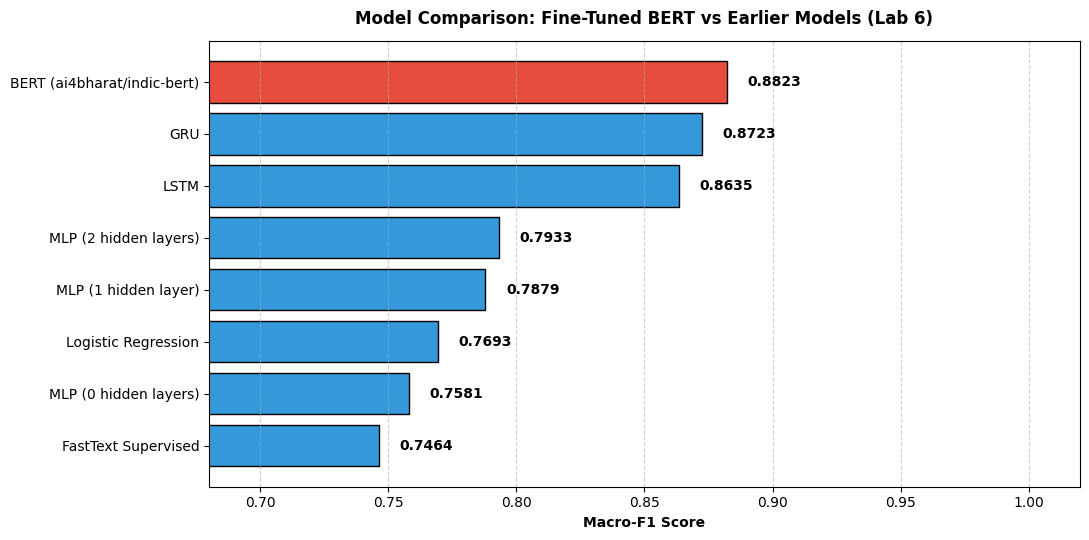

In [17]:
# Benchmark Comparison with Lab 6
benchmark_data = [
    {"Model": "FastText Supervised", "Macro-F1": 0.7464, "Family": "Classical Embedding"},
    {"Model": "MLP (0 hidden layers)", "Macro-F1": 0.7581, "Family": "Feed-Forward Neural Net"},
    {"Model": "Logistic Regression", "Macro-F1": 0.7693, "Family": "Linear Model"},
    {"Model": "MLP (1 hidden layer)", "Macro-F1": 0.7879, "Family": "Feed-Forward Neural Net"},
    {"Model": "MLP (2 hidden layers)", "Macro-F1": 0.7933, "Family": "Feed-Forward Neural Net"},
    {"Model": "LSTM", "Macro-F1": 0.8635, "Family": "Recurrent Neural Net"},
    {"Model": "GRU", "Macro-F1": 0.8723, "Family": "Recurrent Neural Net"},
    {"Model": "BERT (ai4bharat/indic-bert)", "Macro-F1": round(float(test_f1), 4), "Family": "Transformer (Pretrained)"}
]

df_comp = pd.DataFrame(benchmark_data).sort_values("Macro-F1", ascending=True).reset_index(drop=True)
print("=== COMPREHENSIVE BENCHMARK COMPARISON TABLE ===")
print(df_comp.to_string())

# Plot Comparison
plt.figure(figsize=(11, 5.5))
colors = ['#3498DB' if 'BERT' not in m else '#E74C3C' for m in df_comp['Model']]
bars = plt.barh(df_comp['Model'], df_comp['Macro-F1'], color=colors, edgecolor='black')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.008, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va='center', ha='left', fontweight='bold')

plt.xlim(0.68, 1.02)
plt.xlabel("Macro-F1 Score", fontweight='bold')
plt.title("Model Comparison: Fine-Tuned BERT vs Earlier Models (Lab 6)", fontweight='bold', pad=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("/content/bert_vs_earlier_models_f1.png", dpi=300)
plt.show()



### Live Language Prediction Demo


In [18]:
def predict_language(text, top_n=3):
    model.eval()
    enc = tokenizer(text, truncation=True, max_length=64, padding="max_length", return_tensors="pt")
    with torch.no_grad():
        logits = model(input_ids=enc["input_ids"].to(DEVICE), attention_mask=enc["attention_mask"].to(DEVICE)).logits
        probs = torch.softmax(logits, dim=1).squeeze(0)
    top_probs, top_ids = torch.topk(probs, k=top_n)
    print(f"Input: \"{text}\"")
    for p, idx in zip(top_probs, top_ids):
        print(f"  -> {id2label[idx.item()]:20s}: {p.item()*100:.2f}%")
    print("-" * 50)

# Sample sentences across Indian languages
sample_sentences = [
    "કેમ છો, તમે કેવું કામ કરી રહ્યા છો?",                 # Gujarati
    "आज का मौसम बहुत सुहावना और ठंडा है।",            # Hindi
    "কলকাতা ভারতের একটি অন্যতম ঐতিহাসিক শহর।",          # Bengali
    "Welcome to the Indian Language Identification system.", # English
    "ಕನ್ನಡ ಭಾಷೆಯು ಭಾರತದ ಪ್ರಾಚೀನ ಭಾಷೆಗಳಲ್ಲಿ ಒಂದಾಗಿದೆ."     # Kannada
]

print("=== LIVE INFERENCE DEMO ===")
for s in sample_sentences:
    predict_language(s)



=== LIVE INFERENCE DEMO ===
Input: "કેમ છો, તમે કેવું કામ કરી રહ્યા છો?"
  -> Gujarati            : 96.41%
  -> Dogri               : 0.45%
  -> Assamese            : 0.28%
--------------------------------------------------
Input: "आज का मौसम बहुत सुहावना और ठंडा है।"
  -> Hindi               : 68.32%
  -> Bodo                : 15.52%
  -> Dogri               : 7.44%
--------------------------------------------------
Input: "কলকাতা ভারতের একটি অন্যতম ঐতিহাসিক শহর।"
  -> Bengali             : 97.98%
  -> Assamese            : 0.27%
  -> Punjabi             : 0.16%
--------------------------------------------------
Input: "Welcome to the Indian Language Identification system."
  -> English             : 90.52%
  -> Khasi               : 5.59%
  -> Goan Konkani        : 0.67%
--------------------------------------------------
Input: "ಕನ್ನಡ ಭಾಷೆಯು ಭಾರತದ ಪ್ರಾಚೀನ ಭಾಷೆಗಳಲ್ಲಿ ಒಂದಾಗಿದೆ."
  -> Kannada             : 97.83%
  -> Goan Konkani        : 0.26%
  -> Dogri               : 0.19%
--------